# Unit 10: Mengevaluasi Hasil Pemodelan
**Kode unit:** J.62DMI00.014.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** menguji model terbaik dengan data uji yang belum pernah dilihat.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

In [2]:
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

latih = pd.read_csv('../data/processed/latih.csv', parse_dates=['Date'])
uji = pd.read_csv('../data/processed/uji.csv', parse_dates=['Date'])
model = joblib.load('../models/model_terbaik.pkl')
with open('../models/info_model.json') as f:
    info = json.load(f)
FITUR = info['fitur']
X_uji, y_uji = uji[FITUR], uji['target']
print('Model  :', info['model'])
print('Data uji:', len(uji), 'hari,', uji['Date'].min().date(), 's.d.', uji['Date'].max().date())

Model  : Logistic Regression
Data uji: 812 hari, 2023-04-28 s.d. 2026-09-29


## 1. Hasil model dan baseline pada data uji

In [3]:
tebakan = model.predict(X_uji)
peluang = model.predict_proba(X_uji)[:, 1]

baseline = DummyClassifier(strategy='most_frequent').fit(latih[FITUR], latih['target'])
tebak_naik = baseline.predict(X_uji)
tebak_sp500 = (X_uji['sp500_chg'] > 0).astype(int)

tabel = pd.DataFrame([
    {'Model': info['model'], 'Accuracy': accuracy_score(y_uji, tebakan),
     'F1-macro': f1_score(y_uji, tebakan, average='macro'), 'ROC-AUC': roc_auc_score(y_uji, peluang)},
    {'Model': 'Selalu Naik (baseline)', 'Accuracy': accuracy_score(y_uji, tebak_naik),
     'F1-macro': f1_score(y_uji, tebak_naik, average='macro'), 'ROC-AUC': 0.5},
    {'Model': 'Ikuti S&P 500 (baseline)', 'Accuracy': accuracy_score(y_uji, tebak_sp500),
     'F1-macro': f1_score(y_uji, tebak_sp500, average='macro'), 'ROC-AUC': roc_auc_score(y_uji, X_uji['sp500_chg'])},
])
tabel.round(3)

,Model,Accuracy,F1-macro,ROC-AUC
0,Logistic Regression,0.558,0.554,0.583
1,Selalu Naik (baseline),0.522,0.343,0.500
2,Ikuti S&P 500 (baseline),0.546,0.543,0.575


## 2. Apakah target dari Unit 2 tercapai?

In [4]:
m = tabel.iloc[0]
cek = pd.DataFrame([
    ('Accuracy ≥ 0,55', round(m['Accuracy'], 3), m['Accuracy'] >= 0.55),
    ('F1-macro ≥ 0,55', round(m['F1-macro'], 3), m['F1-macro'] >= 0.55),
    ('ROC-AUC ≥ 0,58', round(m['ROC-AUC'], 3), m['ROC-AUC'] >= 0.58),
    ('Accuracy > baseline "Selalu Naik"', round(m['Accuracy'] - tabel.iloc[1]['Accuracy'], 3),
     m['Accuracy'] > tabel.iloc[1]['Accuracy']),
], columns=['Target', 'Nilai', 'Tercapai'])
cek['Tercapai'] = cek['Tercapai'].map({True: 'Ya', False: 'Tidak'})
cek

,Target,Nilai,Tercapai
0,"Accuracy ≥ 0,55",0.558,Ya
1,"F1-macro ≥ 0,55",0.554,Ya
2,"ROC-AUC ≥ 0,58",0.583,Ya
3,"Accuracy > baseline ""Selalu Naik""",0.036,Ya


## 3. Matriks konfusi

              precision    recall  f1-score   support

       Turun       0.54      0.49      0.51       388
        Naik       0.57      0.62      0.60       424

    accuracy                           0.56       812
   macro avg       0.56      0.55      0.55       812
weighted avg       0.56      0.56      0.56       812



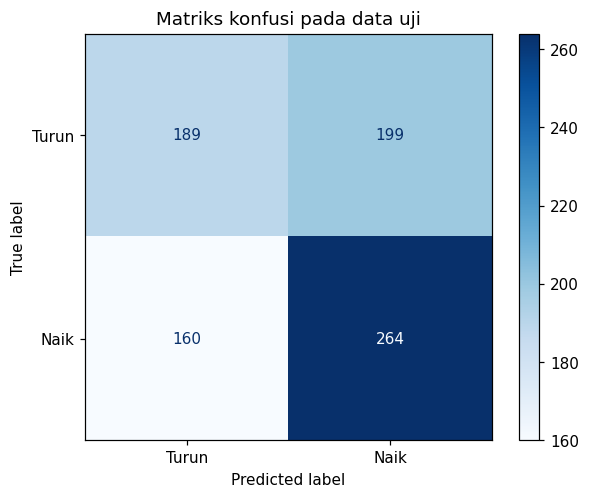

In [5]:
print(classification_report(y_uji, tebakan, target_names=['Turun', 'Naik']))
ConfusionMatrixDisplay(confusion_matrix(y_uji, tebakan), display_labels=['Turun', 'Naik']).plot(cmap='Blues')
plt.title('Matriks konfusi pada data uji')
plt.savefig('../figures/10_matriks_konfusi.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Fitur mana yang paling berpengaruh?

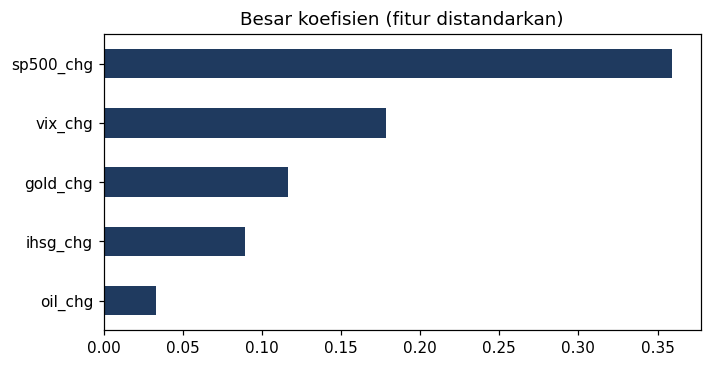

Fitur paling berpengaruh: sp500_chg


In [6]:
est = model[-1] if hasattr(model, 'steps') else model
if hasattr(est, 'feature_importances_'):
    nilai, judul = est.feature_importances_, 'Tingkat kepentingan fitur'
else:
    nilai, judul = np.abs(est.coef_[0]), 'Besar koefisien (fitur distandarkan)'
penting = pd.Series(nilai, index=FITUR).sort_values()
penting.plot(kind='barh', color='#1f3a5f', figsize=(7, 3.5))
plt.title(judul)
plt.savefig('../figures/10_fitur_penting.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fitur paling berpengaruh:', penting.index[-1])

In [7]:
hasil = {'model': info['model'], 'jumlah_hari_uji': len(uji),
         'periode_uji': [str(uji['Date'].min().date()), str(uji['Date'].max().date())],
         'hasil': tabel.round(4).to_dict('records'),
         'target': cek.to_dict('records'),
         'fitur_terpenting': list(penting.index[::-1][:3])}
with open('../models/hasil_evaluasi.json', 'w') as f:
    json.dump(hasil, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

print('KESIMPULAN')
print(f"- Accuracy {m['Accuracy']:.3f}, F1-macro {m['F1-macro']:.3f}, ROC-AUC {m['ROC-AUC']:.3f}")
print(f"- Target tercapai: {(cek['Tercapai'] == 'Ya').sum()} dari {len(cek)}")
print(f"- Dibanding 'Ikuti S&P 500': selisih accuracy {m['Accuracy'] - tabel.iloc[2]['Accuracy']:+.3f}")

KESIMPULAN
- Accuracy 0.558, F1-macro 0.554, ROC-AUC 0.583
- Target tercapai: 4 dari 4
- Dibanding 'Ikuti S&P 500': selisih accuracy +0.012
